# 03 - Baselines (module 2)

Linear baselines for multi-label emotion classification on GoEmotions (28 labels), evaluated with the shared tools of `src/evaluation.py`.

**Protocol (no leakage):**
- **Train** (43,188 comments): fit the TF-IDF vectorizer and the models; choose the hyperparameters by 3-fold cross-validation **inside train**. The vectorizer is in a `Pipeline`, so it is refitted on each training fold.
- **Validation** (5,377): tune one decision threshold per label, compare the models.
- **Test** (5,379): never looked at here. We only save the test probabilities for the final evaluation (module 4).

Input: `data/processed/*.parquet` produced by `01_eda_simple.ipynb` (run it first).

In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, KFold

sys.path.append(os.path.join("..", "src"))
from evaluation import *

SEED = 42
np.random.seed(SEED)

DATA_DIR = os.path.join("..", "data", "processed")
OUT_DIR = os.path.join("..", "results", "baselines")
os.makedirs(OUT_DIR, exist_ok = True)

## 1. Data

In [2]:
df_train = pd.read_parquet(os.path.join(DATA_DIR, "train.parquet"))
df_val = pd.read_parquet(os.path.join(DATA_DIR, "validation.parquet"))
df_test = pd.read_parquet(os.path.join(DATA_DIR, "test.parquet"))

print("Train:", len(df_train), "Validation:", len(df_val), "Test:", len(df_test))
assert (len(df_train), len(df_val), len(df_test)) == (43188, 5377, 5379), "re-run 01_eda_simple.ipynb"

# multi-hot labels, columns in the LABELS_28 order of src/evaluation.py
y_train = to_multi_hot(df_train["labels_28"], LABELS_28)
y_val = to_multi_hot(df_val["labels_28"], LABELS_28)

# true labels of validation at the three levels, for evaluate_all_levels
y_val_levels = {level: to_multi_hot(df_val[level], classes) for level, classes in LEVELS.items()}

print("y_train:", y_train.shape, "y_val:", y_val.shape)

Train: 43188 Validation: 5377 Test: 5379
y_train: (43188, 28) y_val: (5377, 28)


## 2. Trivial references

They show what a model gets without reading the text, and why accuracy-style scores are misleading here.
- **Always neutral:** the most frequent class.
- **Random by frequency:** each label is predicted at random, with its train frequency (`DummyClassifier`, strategy `stratified`).

In [3]:
y_pred_neutral = np.zeros_like(y_val)
y_pred_neutral[:, LABELS_28.index("neutral")] = 1

dummy = DummyClassifier(strategy = "stratified", random_state = SEED)
dummy.fit(np.zeros((len(y_train), 1)), y_train)
y_pred_random = dummy.predict(np.zeros((len(y_val), 1)))

results_trivial = pd.DataFrame([evaluate("Always neutral", y_val, y_pred_neutral),
                                evaluate("Random by frequency", y_val, y_pred_random)])
format_results(results_trivial)

,model,macro_f1,micro_f1,weighted_f1,exact_match
0,Always neutral,"0.018 [0.017, 0.018]","0.301 [0.289, 0.313]",0.137,0.295
1,Random by frequency,"0.044 [0.039, 0.048]","0.130 [0.122, 0.138]",0.129,0.054


## 3. Tokenization: keep punctuation, emojis and capitals

The default `TfidfVectorizer` uses `token_pattern = r"(?u)\b\w\w+\b"` and `lowercase = True`: it drops `!`, `?`, one-letter words like "I", and puts everything in lowercase.
The EDA showed that these carry emotion (81% of curiosity comments contain a `?`, capitals express shouting), so we change both settings. Emojis are already text after the cleaning of notebook 01 (`:face_with_tears_of_joy:`).

In [4]:
TOKEN_PATTERN = r"(?u)\b\w+\b|[^\w\s]"   # words of 1+ characters, or any single punctuation character

examples = ["WHY would you do that?!", "I am SO happy!!! :face_with_tears_of_joy: lol"]

vectorizer_default = TfidfVectorizer()
vectorizer_default.fit(examples)
print("Default:", sorted(vectorizer_default.vocabulary_))

vectorizer_ours = TfidfVectorizer(lowercase = False, token_pattern = TOKEN_PATTERN)
vectorizer_ours.fit(examples)
print("Ours:   ", sorted(vectorizer_ours.vocabulary_))

Default: ['am', 'do', 'face_with_tears_of_joy', 'happy', 'lol', 'so', 'that', 'why', 'would', 'you']
Ours:    ['!', ':', '?', 'I', 'SO', 'WHY', 'am', 'do', 'face_with_tears_of_joy', 'happy', 'lol', 'that', 'would', 'you']


## 4. Thresholds without fooling ourselves

The thresholds are tuned on validation. If we also score validation with those thresholds, the score is optimistic (tuned and measured on the same comments).
To compare models honestly on validation we use **cross-fitting**: split validation in two halves, tune the thresholds on one half and apply them to the other, then swap. Every comment is predicted with thresholds that never saw it.
The final thresholds, used later on test, are tuned on the **whole** validation set.

In [5]:
def crossfit_predict(y_val, proba_val, seed = SEED):
    rng = np.random.RandomState(seed)
    order = rng.permutation(len(y_val))
    half_a, half_b = order[: len(order) // 2], order[len(order) // 2 :]
    y_pred = np.zeros_like(y_val)
    for tune_idx, apply_idx in [(half_a, half_b), (half_b, half_a)]:
        thresholds_half = tune_thresholds(y_val[tune_idx], proba_val[tune_idx])
        y_pred[apply_idx] = apply_thresholds(proba_val[apply_idx], thresholds_half)
    return y_pred


def score_model(name, proba_val):
    # one row at threshold 0.5, one row with cross-fitted per-label thresholds
    rows = [evaluate(name + " (threshold 0.5)", y_val, apply_thresholds(proba_val, 0.5)),
            evaluate(name + " (tuned thresholds)", y_val, crossfit_predict(y_val, proba_val))]
    return pd.DataFrame(rows)

## 5. Main baseline: TF-IDF + logistic regression

- **TF-IDF** on words and pairs of words (1–2 grams), `min_df = 2` (ignore n-grams seen once), `sublinear_tf = True` (log of the counts, so a repeated word does not dominate).
- **One-vs-rest logistic regression:** one binary classifier per label, which fits the multi-label setting (a comment can get several labels).
- **`class_weight = "balanced"`:** errors on rare labels cost more, to fight the imbalance seen in the EDA.

First a fixed, reasonable setting; section 7 tunes it.

In [6]:
def make_vectorizer(ngram_range = (1, 2)):
    return TfidfVectorizer(lowercase = False, token_pattern = TOKEN_PATTERN,
                           ngram_range = ngram_range, min_df = 2, sublinear_tf = True)

pipe_lr = Pipeline([
    ("tfidf", make_vectorizer()),
    ("clf", OneVsRestClassifier(LogisticRegression(C = 4, class_weight = "balanced", solver = "liblinear", max_iter = 1000))),
])

start = time.time()
pipe_lr.fit(df_train["text"], y_train)
proba_val_lr = pipe_lr.predict_proba(df_val["text"])
print("Training time:", round(time.time() - start, 1), "s")

results_lr = score_model("TF-IDF + LogReg", proba_val_lr)
format_results(results_lr)

Training time: 10.6 s


,model,macro_f1,micro_f1,weighted_f1,exact_match
0,TF-IDF + LogReg (threshold 0.5),"0.469 [0.447, 0.485]","0.528 [0.518, 0.538]",0.534,0.329
1,TF-IDF + LogReg (tuned thresholds),"0.463 [0.443, 0.480]","0.527 [0.517, 0.536]",0.535,0.292


## 6. Second baseline: TF-IDF + linear SVM

A linear SVM gives scores, not probabilities. We wrap it in `CalibratedClassifierCV` (Platt scaling, 3 folds inside train) to get probabilities, so it can use the same thresholds and the same `.npy` format as the other models.

In [7]:
pipe_svm = Pipeline([
    ("tfidf", make_vectorizer()),
    ("clf", OneVsRestClassifier(CalibratedClassifierCV(LinearSVC(C = 0.5, class_weight = "balanced"), cv = 3))),
])

start = time.time()
pipe_svm.fit(df_train["text"], y_train)
proba_val_svm = pipe_svm.predict_proba(df_val["text"])
print("Training time:", round(time.time() - start, 1), "s")

results_svm = score_model("TF-IDF + SVM", proba_val_svm)
format_results(results_svm)

Training time: 21.8 s


,model,macro_f1,micro_f1,weighted_f1,exact_match
0,TF-IDF + SVM (threshold 0.5),"0.401 [0.379, 0.418]","0.545 [0.532, 0.557]",0.497,0.479
1,TF-IDF + SVM (tuned thresholds),"0.465 [0.446, 0.481]","0.528 [0.518, 0.538]",0.532,0.311


## 7. AutoML v0.1: model and hyperparameter selection

`GridSearchCV` tries logistic regression, linear SVM and naive Bayes with several settings, by **3-fold cross-validation on train only** (validation and test are not used).

Scoring: **macro average precision** (area under the precision-recall curve, averaged over the 28 labels). It does not depend on a threshold, which fits because the thresholds are tuned afterwards on validation, and like macro-F1 it gives every label the same weight.

In [8]:
pipe_search = Pipeline([
    ("tfidf", make_vectorizer()),
    ("clf", OneVsRestClassifier(LogisticRegression(solver = "liblinear", max_iter = 1000))),
])

param_grid = [
    {   # logistic regression
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "clf__estimator": [LogisticRegression(solver = "liblinear", max_iter = 1000)],
        "clf__estimator__C": [1, 4, 10],
        "clf__estimator__class_weight": [None, "balanced"],
    },
    {   # linear SVM (calibrated to get probabilities)
        "tfidf__ngram_range": [(1, 2)],
        "clf__estimator": [CalibratedClassifierCV(LinearSVC(class_weight = "balanced"), cv = 3)],
        "clf__estimator__estimator__C": [0.1, 0.5],
    },
    {   # multinomial naive Bayes
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "clf__estimator": [MultinomialNB()],
        "clf__estimator__alpha": [0.1, 0.5],
    },
]

search = GridSearchCV(pipe_search, param_grid,
                      scoring = "average_precision",
                      cv = KFold(n_splits = 3, shuffle = True, random_state = SEED),
                      n_jobs = -1, refit = True)

start = time.time()
search.fit(df_train["text"], y_train)
print("Search time:", round((time.time() - start) / 60, 1), "min")
print("Best CV macro average precision:", round(search.best_score_, 3))
print("Best setting:", search.best_params_)

Search time: 2.4 min
Best CV macro average precision: 0.394
Best setting: {'clf__estimator': LogisticRegression(max_iter=1000, solver='liblinear'), 'clf__estimator__C': 4, 'clf__estimator__class_weight': None, 'tfidf__ngram_range': (1, 1)}


In [9]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results["model"] = cv_results["param_clf__estimator"].apply(lambda e: type(e).__name__)
cv_table = cv_results[["model", "param_tfidf__ngram_range", "param_clf__estimator__C",
                       "param_clf__estimator__class_weight", "param_clf__estimator__estimator__C",
                       "param_clf__estimator__alpha", "mean_test_score", "std_test_score"]]
cv_table = cv_table.sort_values("mean_test_score", ascending = False).round(3)
cv_table.to_csv(os.path.join(OUT_DIR, "automl_cv_results.csv"), index = False)
cv_table.head(10)

,model,param_tfidf__ngram_range,param_clf__estimator__C,param_clf__estimator__class_weight,param_clf__estimator__estimator__C,param_clf__estimator__alpha,mean_test_score,std_test_score
4,LogisticRegression,"(1, 1)",4.0,NaN,NaN,NaN,0.394,0.006
5,LogisticRegression,"(1, 2)",4.0,NaN,NaN,NaN,0.392,0.009
13,CalibratedClassifierCV,"(1, 2)",NaN,NaN,0.5,NaN,0.390,0.010
9,LogisticRegression,"(1, 2)",10.0,NaN,NaN,NaN,0.388,0.009
7,LogisticRegression,"(1, 2)",4.0,balanced,NaN,NaN,0.387,0.009
0,LogisticRegression,"(1, 1)",1.0,NaN,NaN,NaN,0.386,0.006
11,LogisticRegression,"(1, 2)",10.0,balanced,NaN,NaN,0.384,0.009
12,CalibratedClassifierCV,"(1, 2)",NaN,NaN,0.1,NaN,0.383,0.009
3,LogisticRegression,"(1, 2)",1.0,balanced,NaN,NaN,0.383,0.009
8,LogisticRegression,"(1, 1)",10.0,NaN,NaN,NaN,0.382,0.005


In [10]:
# the best pipeline is refitted on the whole train set by GridSearchCV (refit = True)
best_pipe = search.best_estimator_
proba_val_best = best_pipe.predict_proba(df_val["text"])

results_best = score_model("AutoML v0.1 best", proba_val_best)
format_results(results_best)

,model,macro_f1,micro_f1,weighted_f1,exact_match
0,AutoML v0.1 best (threshold 0.5),"0.384 [0.365, 0.400]","0.543 [0.531, 0.556]",0.501,0.473
1,AutoML v0.1 best (tuned thresholds),"0.477 [0.456, 0.495]","0.521 [0.512, 0.530]",0.535,0.309


## 8. Character n-grams (feature experiment)

Character n-grams (2 to 5 characters inside words) are robust to typos and word variants ("lol", "lool", "loool") and keep punctuation automatically. One fit with the best classifier, compared on validation.

In [11]:
pipe_char = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer = "char_wb", ngram_range = (2, 5), min_df = 3,
                              sublinear_tf = True, lowercase = False)),
    ("clf", OneVsRestClassifier(LogisticRegression(C = 4, class_weight = "balanced", solver = "liblinear", max_iter = 1000))),
])

start = time.time()
pipe_char.fit(df_train["text"], y_train)
proba_val_char = pipe_char.predict_proba(df_val["text"])
print("Training time:", round(time.time() - start, 1), "s")

results_char = score_model("Char TF-IDF + LogReg", proba_val_char)
format_results(results_char)

Training time: 105.5 s


,model,macro_f1,micro_f1,weighted_f1,exact_match
0,Char TF-IDF + LogReg (threshold 0.5),"0.448 [0.430, 0.463]","0.493 [0.484, 0.501]",0.521,0.230
1,Char TF-IDF + LogReg (tuned thresholds),"0.468 [0.449, 0.485]","0.523 [0.514, 0.532]",0.535,0.302


## 9. Comparison on validation (28 labels)

In [12]:
results_all = pd.concat([results_trivial, results_lr, results_svm, results_best, results_char], ignore_index = True)
results_all.to_csv(os.path.join(OUT_DIR, "validation_results_28.csv"), index = False)
format_results(results_all)[["model", "macro_f1", "micro_f1", "weighted_f1", "exact_match"]]

,model,macro_f1,micro_f1,weighted_f1,exact_match
0,Always neutral,"0.018 [0.017, 0.018]","0.301 [0.289, 0.313]",0.137,0.295
1,Random by frequency,"0.044 [0.039, 0.048]","0.130 [0.122, 0.138]",0.129,0.054
2,TF-IDF + LogReg (threshold 0.5),"0.469 [0.447, 0.485]","0.528 [0.518, 0.538]",0.534,0.329
3,TF-IDF + LogReg (tuned thresholds),"0.463 [0.443, 0.480]","0.527 [0.517, 0.536]",0.535,0.292
4,TF-IDF + SVM (threshold 0.5),"0.401 [0.379, 0.418]","0.545 [0.532, 0.557]",0.497,0.479
5,TF-IDF + SVM (tuned thresholds),"0.465 [0.446, 0.481]","0.528 [0.518, 0.538]",0.532,0.311
6,AutoML v0.1 best (threshold 0.5),"0.384 [0.365, 0.400]","0.543 [0.531, 0.556]",0.501,0.473
7,AutoML v0.1 best (tuned thresholds),"0.477 [0.456, 0.495]","0.521 [0.512, 0.530]",0.535,0.309
8,Char TF-IDF + LogReg (threshold 0.5),"0.448 [0.430, 0.463]","0.493 [0.484, 0.501]",0.521,0.230
9,Char TF-IDF + LogReg (tuned thresholds),"0.468 [0.449, 0.485]","0.523 [0.514, 0.532]",0.535,0.302


Is the tuned best model really better than the fixed logistic regression? Paired bootstrap on the same validation comments (B − A, 95% CI):

In [13]:
y_pred_lr = crossfit_predict(y_val, proba_val_lr)
y_pred_best = crossfit_predict(y_val, proba_val_best)
paired_bootstrap(y_val, y_pred_lr, y_pred_best)

{'diff_b_minus_a': 0.013740178853427543,
 'ci_low': 0.00045024692752566187,
 'ci_high': 0.02724814057735694,
 'share_b_not_better': 0.018}

## 10. The three levels: 28 labels, Ekman, sentiment

The 28-label predictions of the best model are regrouped with the official mappings (`regroup_predictions`): a group is predicted when at least one of its emotions is.

In [14]:
results_levels = evaluate_all_levels("AutoML v0.1 best", y_pred_best, y_val_levels)
results_levels.to_csv(os.path.join(OUT_DIR, "validation_results_levels.csv"), index = False)
format_results(results_levels)[["level", "macro_f1", "micro_f1", "exact_match"]]

,level,macro_f1,micro_f1,exact_match
0,28,"0.477 [0.456, 0.495]","0.521 [0.512, 0.530]",0.309
1,ekman,"0.546 [0.527, 0.564]","0.620 [0.611, 0.630]",0.424
2,sentiment,"0.615 [0.604, 0.625]","0.646 [0.636, 0.655]",0.447


## 11. Where the baseline fails: per-label results

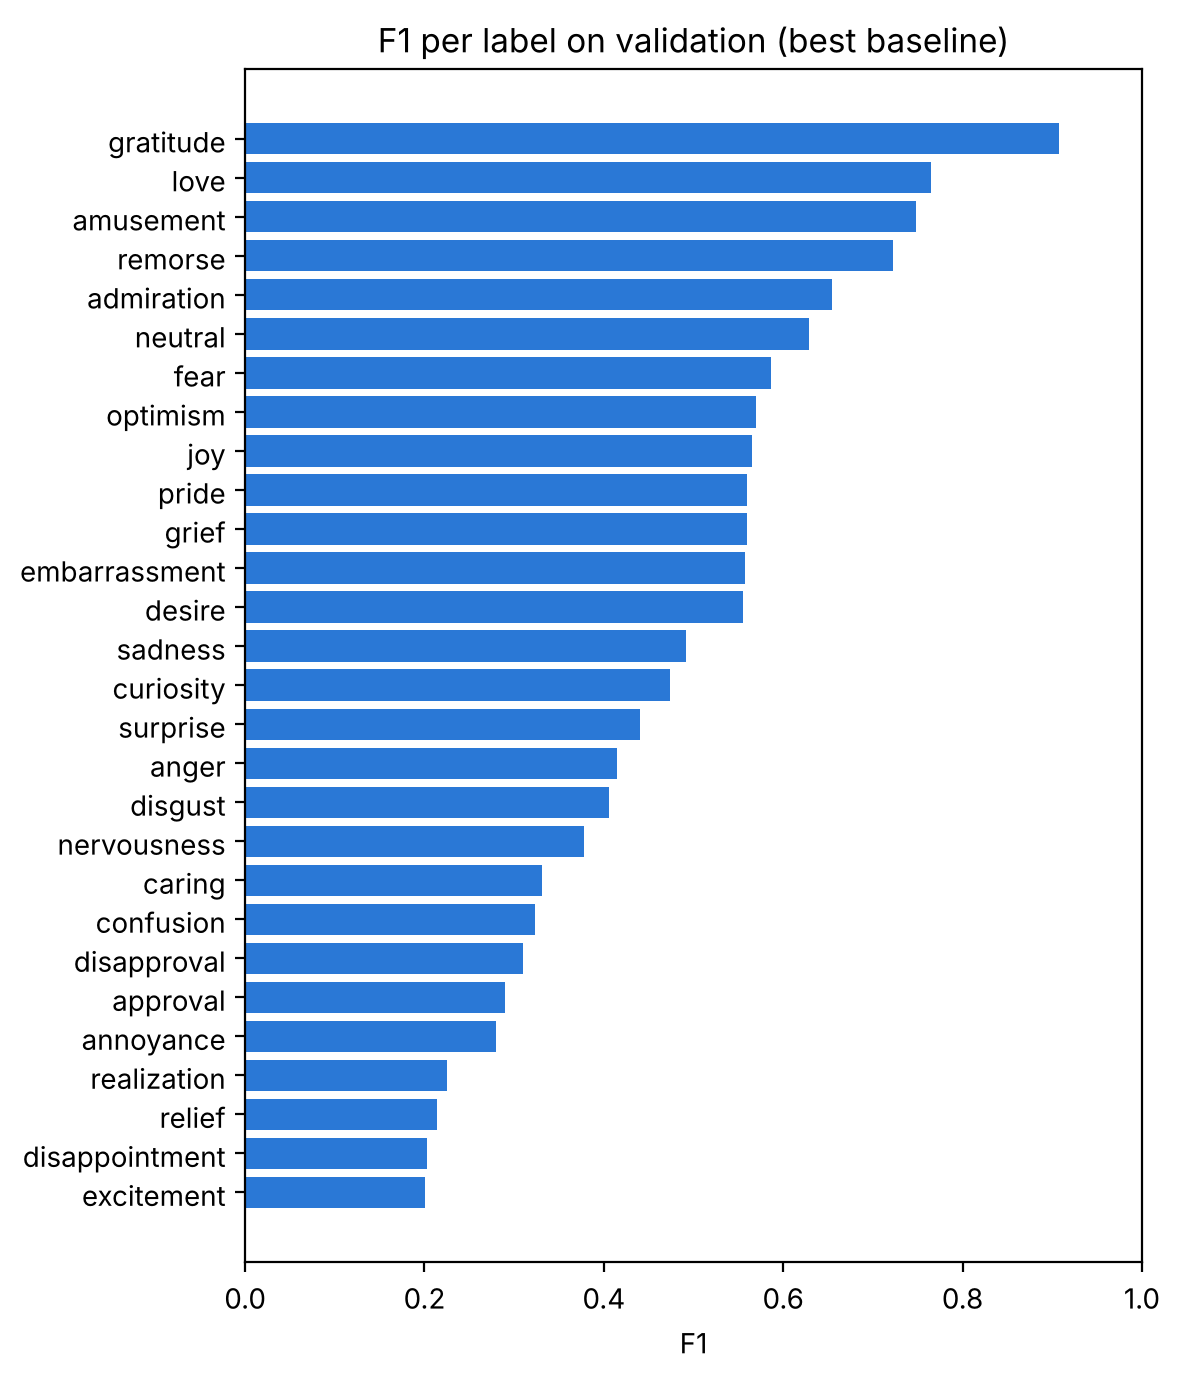

In [15]:
report_best = per_class_report(y_val, y_pred_best, LABELS_28)
report_best.to_csv(os.path.join(OUT_DIR, "per_class_validation.csv"))
plot_per_class_f1(report_best, "F1 per label on validation (best baseline)", os.path.join(OUT_DIR, "per_class_f1.png"))
plt.show()

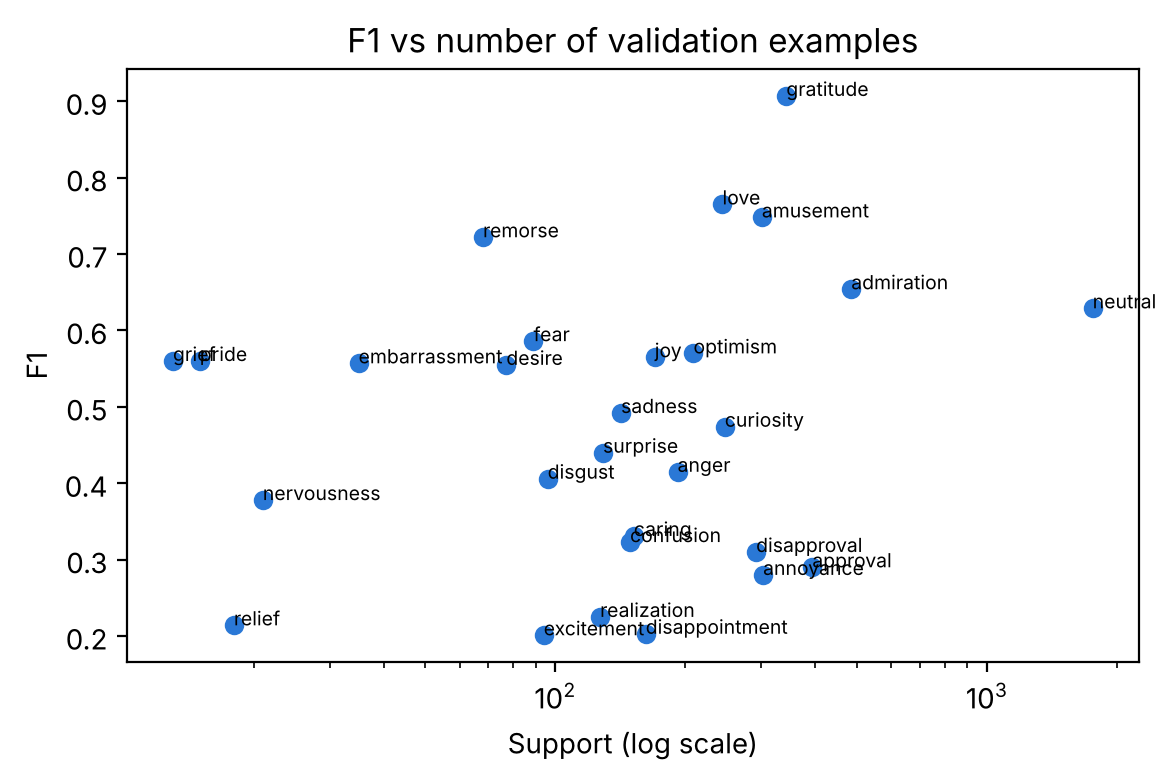

In [16]:
plot_f1_vs_support(report_best, "F1 vs number of validation examples", os.path.join(OUT_DIR, "f1_vs_support.png"))
plt.show()

## 12. What the model looks at

For a linear model on TF-IDF, each n-gram has one weight per label. The largest weights show what drives each prediction, a check that the model learned sensible cues and not artefacts.

In [17]:
tfidf_best = best_pipe.named_steps["tfidf"]
clf_best = best_pipe.named_steps["clf"]
vocab = np.array(tfidf_best.get_feature_names_out())

if hasattr(clf_best.estimators_[0], "coef_"):
    for emotion in ["gratitude", "amusement", "anger", "curiosity", "sadness", "fear"]:
        weights = clf_best.estimators_[LABELS_28.index(emotion)].coef_.ravel()
        top = vocab[np.argsort(-weights)[:10]]
        print(emotion, ":", ", ".join(top))
else:
    print("The best model has no linear weights to show (", type(clf_best.estimators_[0]).__name__, ")")

gratitude : Thanks, Thank, thanks, thank, welcome, congrats, Congrats, Welcome, THANK, thankful
amusement : lol, Lol, haha, funny, hilarious, LOL, Haha, Funny, lmao, fun
anger : hate, fuck, Fuck, fucking, angry, hell, Shut, dare, anger, asshole
curiosity : ?, curious, curiosity, interesting, wondering, Curious, wonder, How, Interesting, Are
sadness : sad, Sadly, sadly, Sad, painful, hurts, saddest, miss, sadness, sorry
fear : scared, afraid, scary, terrifying, terrible, fear, horrible, scares, dangerous, cringe


## 13. Save probabilities and thresholds for module 4

Format agreed with Myriam: `.npy` arrays of shape `(n, 28)`, columns in the `LABELS_28` order, rows in the order of `data/processed/*.parquet`.
The test probabilities are only **saved**: no test score is computed in this notebook.

In [18]:
thresholds_best = tune_thresholds(y_val, proba_val_best)   # final thresholds: tuned on the whole validation set
proba_test_best = best_pipe.predict_proba(df_test["text"])
proba_test_lr = pipe_lr.predict_proba(df_test["text"])

np.save(os.path.join(OUT_DIR, "proba_val_best.npy"), proba_val_best.astype(np.float32))
np.save(os.path.join(OUT_DIR, "proba_test_best.npy"), proba_test_best.astype(np.float32))
np.save(os.path.join(OUT_DIR, "thresholds_best.npy"), thresholds_best)
np.save(os.path.join(OUT_DIR, "proba_val_logreg.npy"), proba_val_lr.astype(np.float32))
np.save(os.path.join(OUT_DIR, "proba_test_logreg.npy"), proba_test_lr.astype(np.float32))

print("Saved in", OUT_DIR)
print("proba_val_best:", proba_val_best.shape, "proba_test_best:", proba_test_best.shape)
pd.Series(thresholds_best, index = LABELS_28).round(2).sort_values()

Saved in ../results/baselines
proba_val_best: (5377, 28) proba_test_best: (5379, 28)


remorse           0.06
pride             0.06
disappointment    0.07
relief            0.07
grief             0.07
disgust           0.09
nervousness       0.09
embarrassment     0.10
fear              0.11
confusion         0.11
annoyance         0.11
joy               0.12
caring            0.12
surprise          0.12
disapproval       0.13
anger             0.14
curiosity         0.14
realization       0.14
approval          0.15
amusement         0.15
excitement        0.15
sadness           0.20
admiration        0.21
desire            0.21
optimism          0.22
love              0.27
neutral           0.27
gratitude         0.41
dtype: float64

## 14. Summary (validation set)

**Results, 28 labels** (macro-F1 with bootstrap 95% CI; per-label thresholds cross-fitted on validation):

| Model | Macro-F1 | Micro-F1 |
|---|---|---|
| Always neutral | 0.018 | 0.301 |
| Random by frequency | 0.044 | 0.130 |
| TF-IDF + LogReg (C = 4, balanced, 1–2 grams), threshold 0.5 | 0.469 [0.447, 0.485] | 0.528 |
| TF-IDF + linear SVM, tuned thresholds | 0.465 [0.446, 0.481] | 0.528 |
| Char TF-IDF + LogReg, tuned thresholds | 0.468 [0.449, 0.485] | 0.523 |
| **AutoML v0.1 best (LogReg, C = 4, unigrams, no class weight), tuned thresholds** | **0.477 [0.456, 0.495]** | 0.521 |

**Main findings**
- **Trivial models fail on macro-F1:** always predicting neutral gets 0.30 micro-F1 but only 0.018 macro-F1, which confirms macro-F1 as the primary metric.
- **All linear models land close together** (0.46 to 0.48): the choice of classifier matters less than handling the imbalance. The AutoML best model is significantly better than the fixed logistic regression (paired bootstrap: +0.014, 95% CI [0.000, 0.027]), but the gain is small.
- **Imbalance handling:** per-label thresholds and `class_weight = "balanced"` do the same job. A model without class weights is poor at threshold 0.5 (0.384) but becomes the best once thresholds are tuned. Tuned thresholds are low (0.06 to 0.41), because rare labels rarely reach a probability of 0.5.
- **Three levels:** macro-F1 rises from 0.477 (28 labels) to 0.546 (Ekman) and 0.615 (sentiment), so a large part of the errors are confusions between close emotions of the same group.
- **Per label:** gratitude (0.91), love (0.77) and amusement (0.75) are easy because they have explicit cue words. The weakest are excitement (0.20), disappointment (0.20), relief (0.21) and realization (0.23); approval and annoyance are low too (0.29, 0.28) despite many examples, because they are expressed without fixed words.
- **The model learned sensible cues:** "thanks" for gratitude, "lol / haha" for amusement, "?" for curiosity, "scared / afraid" for fear. Keeping punctuation and capitals (section 3) is visible in these weights.
- **Character n-grams** do not beat words (0.468) and train 10 times slower.

**Limits:** the validation scores with tuned thresholds are cross-fitted, but validation was also used to compare many models, so the final number will come from the test set, once, in module 4. The test probabilities are saved in `results/baselines/` for that, and the thresholds used for test are tuned on the whole validation set.

**Next (week 3):** the transformer (module 3) must beat **0.477 macro-F1** on the same splits to justify its cost.